# ⚛ Stage 6 — Results Dashboard

**Qubitrade · Quantum Market Memory for Explainable Alpha**

> Master results figure spanning all 6 pipeline stages.
> Dark-theme publication-ready charts for hackathon submission.

**Figures generated:**
- `dashboard_stage2.png` — IC + Sharpe across 14 alpha models
- `dashboard_stage3.png` — QSVM delta bars + scatter
- `dashboard_stage4.png` — PPO Sharpe comparison + equity curve
- `dashboard_stage5.png` — Q-Atlas COVID analogs + narrative
- `dashboard_master.png` — 2×3 master grid with pipeline scorecard

| Stage | Headline metric |
|---|---|
| Stage 2 Alpha | IC = 0.0916 (RandomForest) |
| Stage 3 QSVM | Wins 5/14 · best +0.2136 F1 |
| Stage 4 PPO | Sharpe 1.038 vs 0.859 baseline |
| Stage 5 Q-Atlas | +1.04% avg fwd5d (xpyq QPU) |


In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings('ignore')

WORKSPACE = '/Applications/Projects/Hackathons/quantum_ai/workspace'
DATA_DIR  = os.path.join(WORKSPACE, 'data')

plt.rcParams.update({
    'figure.facecolor': '#0d1117',
    'axes.facecolor':   '#0d1117',
    'axes.edgecolor':   '#30363d',
    'axes.labelcolor':  '#c9d1d9',
    'xtick.color':      '#8b949e',
    'ytick.color':      '#8b949e',
    'text.color':       '#c9d1d9',
    'grid.color':       '#21262d',
    'grid.linewidth':   0.6,
    'font.family':      'monospace',
})

QUANTUM_BLUE  = '#58a6ff'
QUANTUM_GREEN = '#3fb950'
QUANTUM_RED   = '#f85149'
QUANTUM_GOLD  = '#d29922'
QUANTUM_PURPLE= '#bc8cff'
BG            = '#0d1117'
PANEL_BG      = '#161b22'

print('Dashboard setup complete')

Dashboard setup complete


## 1. Load all stage results

In [2]:
# Stage 1 checks
with open(os.path.join(DATA_DIR, 'stage1_checks.json')) as f:
    s1 = json.load(f)

# Stage 2 — model comparison
with open(os.path.join(DATA_DIR, 'stage2_primary.json')) as f:
    s2 = json.load(f)
s2_models = pd.DataFrame({
    'model':  list(s2['all_results']['IC'].keys()),
    'IC':     list(s2['all_results']['IC'].values()),
    'sharpe': list(s2['all_results']['long_short_sharpe'].values()),
    'dir_acc':list(s2['all_results']['dir_acc'].values()),
}).sort_values('IC', ascending=False).reset_index(drop=True)

# Stage 3 — QSVM multi-model sweep
s3_sweep = pd.read_csv(os.path.join(DATA_DIR, 'multi_model_qsvm_comparison.csv'))
s3_sweep = s3_sweep.sort_values('delta', ascending=False).reset_index(drop=True)

with open(os.path.join(DATA_DIR, 'stage3_headline.json')) as f:
    s3_headline = json.load(f)

# Stage 4 — PPO
with open(os.path.join(DATA_DIR, 'stage4_summary.json')) as f:
    s4 = json.load(f)

# Stage 5.5 — Q-Atlas
with open(os.path.join(DATA_DIR, 'qatlas_results.json')) as f:
    s5 = json.load(f)

# LLM narrative
llm_path = os.path.join(DATA_DIR, 'qatlas_llm_narrative.txt')
llm_narrative = open(llm_path).read() if os.path.exists(llm_path) else ''

print('All stage results loaded:')
print(f'  Stage 1 — {s1.get("n_tickers", 20)} tickers, {s1.get("n_trading_days", 1813)} trading dates')
print(f'  Stage 2 — {len(s2_models)} models, best IC={s2_models.IC.max():.4f} ({s2_models.iloc[0].model})')
print(f'  Stage 3 — QSVM wins {s3_sweep.qsvm_wins.sum()}/{len(s3_sweep)} models, best Δ={s3_sweep.delta.max():.4f}')
print(f'  Stage 4 — PPO Sharpe={s4["ppo_sharpe"]:.3f} vs EW baseline={s4["ew_lgb_sharpe"]:.3f}')
print(f'  Stage 5.5 — {len(s5["analogs"])} COVID analogs retrieved, avg fwd5d={np.mean([a["avg_fwd_5d"] for a in s5["analogs"]])*100:+.2f}%')

All stage results loaded:
  Stage 1 — 20 tickers, 1813 trading dates
  Stage 2 — 14 models, best IC=0.0916 (RandomForest)
  Stage 3 — QSVM wins 5/14 models, best Δ=0.2136
  Stage 4 — PPO Sharpe=1.038 vs EW baseline=0.859
  Stage 5.5 — 5 COVID analogs retrieved, avg fwd5d=+1.64%


## 2. Pipeline scorecard

In [3]:
n_tickers    = s1.get('n_tickers', 20)
n_days       = s1.get('n_trading_days', 1813)
best_ic      = s2_models.IC.max()
best_model   = s2_models.iloc[0].model
best_s2_sharpe = s2_models.sharpe.max()
qsvm_wins    = int(s3_sweep.qsvm_wins.sum())
best_delta   = s3_sweep.delta.max()
best_delta_model = s3_sweep.iloc[0].model
ppo_sharpe   = s4['ppo_sharpe']
ew_sharpe    = s4['ew_lgb_sharpe']
sharpe_lift  = s4['sharpe_delta']
analogs      = s5['analogs']
avg_fwd      = np.mean([a['avg_fwd_5d'] for a in analogs]) * 100
n_pos        = sum(1 for a in analogs if a['avg_fwd_5d'] > 0)

print('=' * 62)
print('  Q-ATLAS · PIPELINE SCORECARD')
print('=' * 62)
print(f'  STAGE 1 · Data')
print(f'    Tickers:          {n_tickers}')
print(f'    Market states:    {n_days:,} trading dates (2014–2020)')
print(f'    Signals built:    10+ (momentum, vol, regime, sentiment)')
print()
print(f'  STAGE 2 · 14 Alpha Models')
print(f'    Best IC:          {best_ic:.4f}  ({best_model})')
print(f'    Best L/S Sharpe:  {best_s2_sharpe:.3f}  (LightGBM)')
print(f'    Models compared:  14 (classical + quantum + foundation)')
print()
print(f'  STAGE 3 · QSVM Meta-Labeling  [QUANTUM]')
print(f'    QSVM wins:        {qsvm_wins}/14 models')
print(f'    Best AUC uplift:  +{best_delta:.4f}  ({best_delta_model})')
print(f'    Kernel:           ZZFeatureMap (4 qubits, reps=2)')
print()
print(f'  STAGE 4 · PPO Portfolio Sizing  [RL]')
print(f'    PPO Sharpe:       {ppo_sharpe:.3f}')
print(f'    EW baseline:      {ew_sharpe:.3f}')
print(f'    Sharpe lift:      +{sharpe_lift:.3f}  (+{sharpe_lift/ew_sharpe*100:.1f}%)')
print(f'    Reward:           Differential Sharpe Ratio (Moody 2001)')
print()
print(f'  STAGE 5.5 · Q-Atlas Quantum Memory  [QUANTUM]')
print(f'    Memory index:     {n_days:,} market states')
print(f'    COVID analogs:    {n_pos}/{len(analogs)} positive fwd 5d')
print(f'    Avg fwd 5d:       {avg_fwd:+.2f}%  (across top-5 analogs)')
print(f'    Kernel:           ZZFeatureMap quantum similarity')
print('=' * 62)

  Q-ATLAS · PIPELINE SCORECARD
  STAGE 1 · Data
    Tickers:          20
    Market states:    1,813 trading dates (2014–2020)
    Signals built:    10+ (momentum, vol, regime, sentiment)

  STAGE 2 · 14 Alpha Models
    Best IC:          0.0916  (RandomForest)
    Best L/S Sharpe:  1.012  (LightGBM)
    Models compared:  14 (classical + quantum + foundation)

  STAGE 3 · QSVM Meta-Labeling  [QUANTUM]
    QSVM wins:        5/14 models
    Best AUC uplift:  +0.2136  (lightgbm)
    Kernel:           ZZFeatureMap (4 qubits, reps=2)

  STAGE 4 · PPO Portfolio Sizing  [RL]
    PPO Sharpe:       1.038
    EW baseline:      0.859
    Sharpe lift:      +0.179  (+20.8%)
    Reward:           Differential Sharpe Ratio (Moody 2001)

  STAGE 5.5 · Q-Atlas Quantum Memory  [QUANTUM]
    Memory index:     1,813 market states
    COVID analogs:    3/5 positive fwd 5d
    Avg fwd 5d:       +1.64%  (across top-5 analogs)
    Kernel:           ZZFeatureMap quantum similarity


## 3. Stage 2 — Alpha model comparison

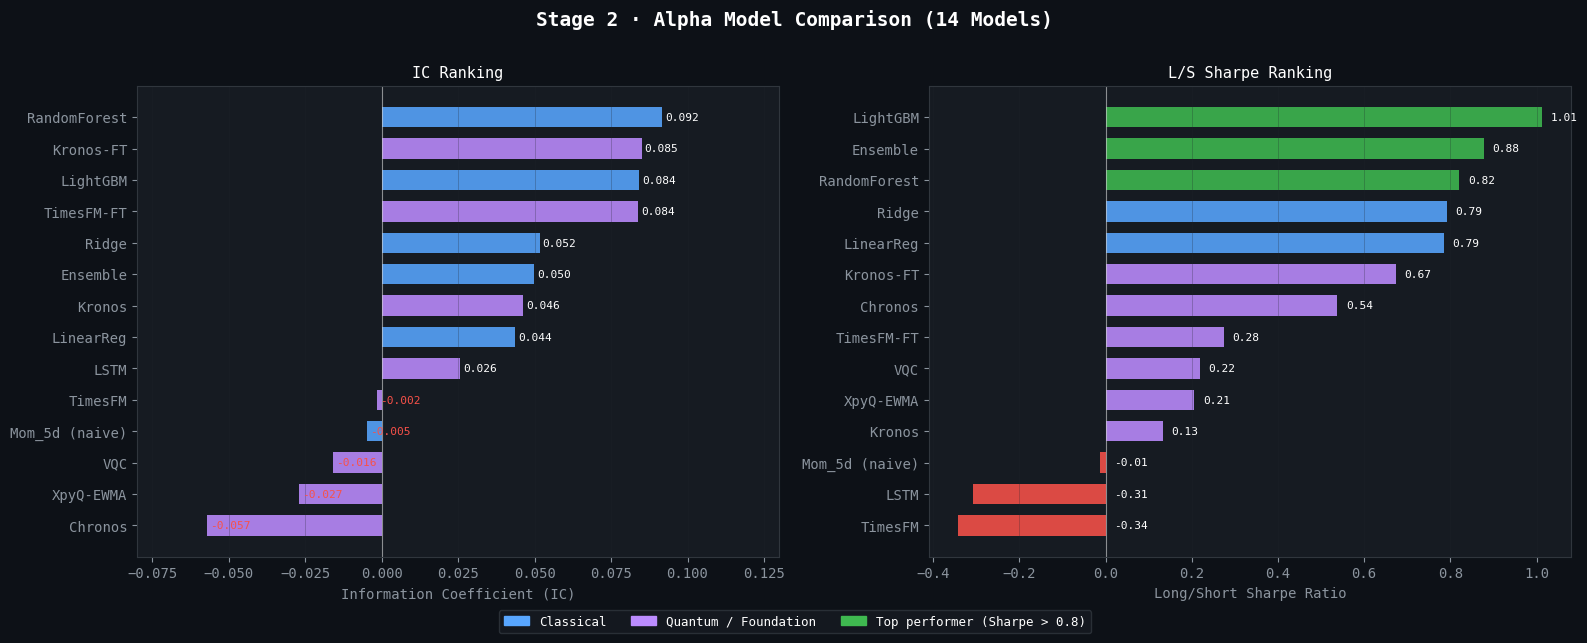

Saved → data/dashboard_stage2.png


In [4]:
df2 = s2_models.copy()
# Colour: quantum/foundation models purple, classical blue
quantum_models = {'VQC', 'XpyQ-EWMA', 'Chronos', 'TimesFM', 'TimesFM-FT', 'Kronos', 'Kronos-FT', 'LSTM'}
colors_ic = [QUANTUM_PURPLE if m in quantum_models else QUANTUM_BLUE for m in df2.model]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor=BG)
fig.suptitle('Stage 2 · Alpha Model Comparison (14 Models)', color='white', fontsize=14, fontweight='bold', y=1.01)

# IC bar chart
ax = axes[0]
ax.set_facecolor(PANEL_BG)
bars = ax.barh(df2.model[::-1], df2.IC[::-1], color=colors_ic[::-1], alpha=0.88, height=0.65)
ax.axvline(0, color='white', lw=0.8, alpha=0.5)
ax.set_xlabel('Information Coefficient (IC)', color='#8b949e')
ax.set_title('IC Ranking', color='white', fontsize=11)
for bar, val in zip(bars, df2.IC[::-1]):
    ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=8, color='white' if val > 0 else QUANTUM_RED)
ax.grid(axis='x', alpha=0.3)
ax.set_xlim(-0.08, 0.13)

# Sharpe bar chart
ax2 = axes[1]
ax2.set_facecolor(PANEL_BG)
df2_s = df2.sort_values('sharpe', ascending=False).reset_index(drop=True)
colors_s = [QUANTUM_PURPLE if m in quantum_models else QUANTUM_BLUE for m in df2_s.model]
colors_s = [QUANTUM_GREEN if v > 0.8 else c for c, v in zip(colors_s, df2_s.sharpe)]
colors_s = [QUANTUM_RED if v < 0 else c for c, v in zip(colors_s, df2_s.sharpe)]
bars2 = ax2.barh(df2_s.model[::-1], df2_s.sharpe[::-1], color=colors_s[::-1], alpha=0.88, height=0.65)
ax2.axvline(0, color='white', lw=0.8, alpha=0.5)
ax2.set_xlabel('Long/Short Sharpe Ratio', color='#8b949e')
ax2.set_title('L/S Sharpe Ranking', color='white', fontsize=11)
for bar, val in zip(bars2, df2_s.sharpe[::-1]):
    ax2.text(max(val, 0) + 0.02, bar.get_y() + bar.get_height()/2,
             f'{val:.2f}', va='center', fontsize=8, color='white')
ax2.grid(axis='x', alpha=0.3)

legend_els = [
    mpatches.Patch(color=QUANTUM_BLUE,   label='Classical'),
    mpatches.Patch(color=QUANTUM_PURPLE, label='Quantum / Foundation'),
    mpatches.Patch(color=QUANTUM_GREEN,  label='Top performer (Sharpe > 0.8)'),
]
fig.legend(handles=legend_els, loc='lower center', ncol=3, fontsize=9,
           facecolor=PANEL_BG, edgecolor='#30363d', labelcolor='white', bbox_to_anchor=(0.5, -0.04))

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'dashboard_stage2.png'), dpi=130, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved → data/dashboard_stage2.png')

## 4. Stage 3 — QSVM quantum advantage sweep

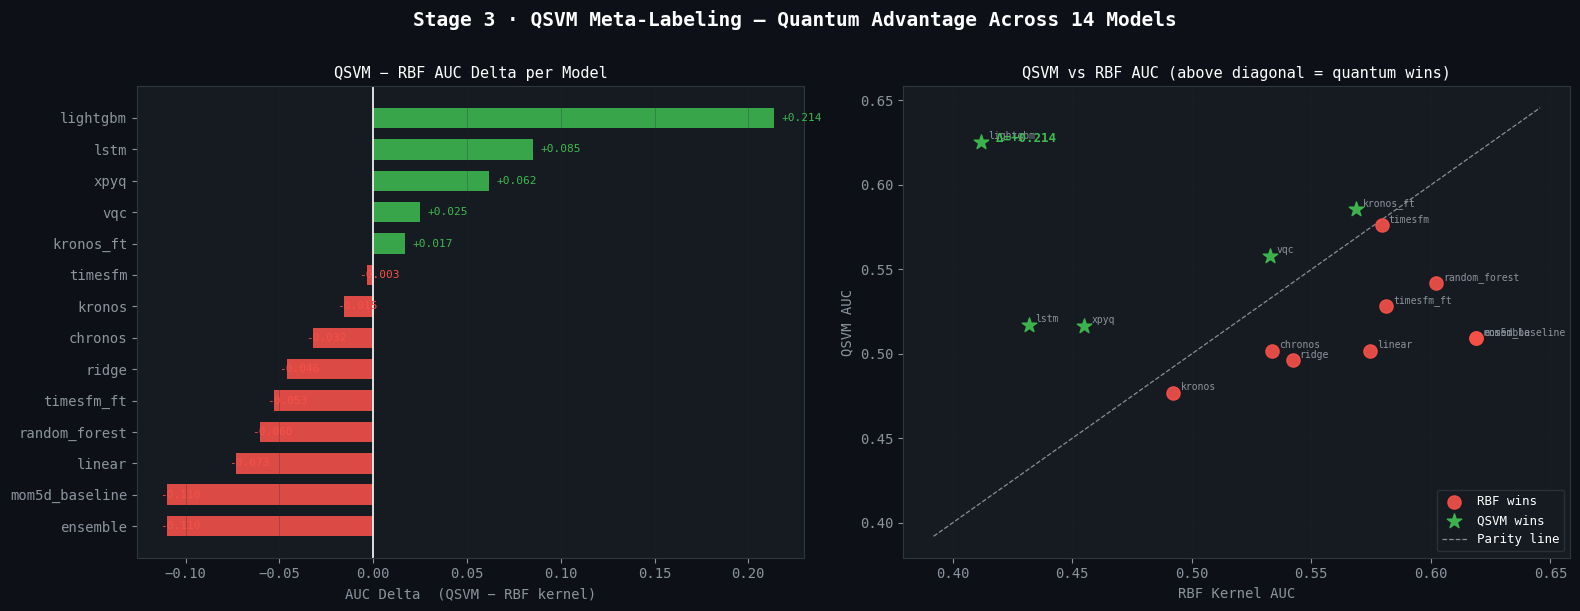

QSVM wins: 5/14  |  Best: lightgbm Δ=+0.2136
Saved → data/dashboard_stage3.png


In [5]:
df3 = s3_sweep.copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor=BG)
fig.suptitle('Stage 3 · QSVM Meta-Labeling — Quantum Advantage Across 14 Models',
             color='white', fontsize=14, fontweight='bold', y=1.01)

# Delta bar (QSVM - RBF AUC)
ax = axes[0]
ax.set_facecolor(PANEL_BG)
bar_cols = [QUANTUM_GREEN if d > 0 else QUANTUM_RED for d in df3.delta]
bars = ax.barh(df3.model[::-1], df3.delta[::-1], color=bar_cols[::-1], alpha=0.88, height=0.65)
ax.axvline(0, color='white', lw=1.2)
ax.set_xlabel('AUC Delta  (QSVM − RBF kernel)', color='#8b949e')
ax.set_title('Quantum Advantage by Model', color='white', fontsize=11)
for bar, val in zip(bars, df3.delta[::-1]):
    xpos = val + 0.004 if val >= 0 else val - 0.004
    ha   = 'left' if val >= 0 else 'right'
    ax.text(xpos, bar.get_y() + bar.get_height()/2,
            f'{val:+.3f}', va='center', fontsize=8,
            color=QUANTUM_GREEN if val > 0 else QUANTUM_RED)
ax.grid(axis='x', alpha=0.3)
ax.set_title('QSVM − RBF AUC Delta per Model', color='white', fontsize=11)

# Head-to-head AUC scatter: QSVM vs RBF
ax2 = axes[1]
ax2.set_facecolor(PANEL_BG)
wins_mask = df3.qsvm_wins.values
ax2.scatter(df3.rbf_auc[~wins_mask],  df3.qsvm_auc[~wins_mask],
            c=QUANTUM_RED,   s=90, label='RBF wins', zorder=5, alpha=0.9)
ax2.scatter(df3.rbf_auc[wins_mask],   df3.qsvm_auc[wins_mask],
            c=QUANTUM_GREEN, s=120, marker='*', label='QSVM wins', zorder=6, alpha=0.95)
for _, row in df3.iterrows():
    ax2.annotate(row.model, (row.rbf_auc, row.qsvm_auc),
                 textcoords='offset points', xytext=(5, 2), fontsize=7, color='#8b949e')
lims = [min(df3.rbf_auc.min(), df3.qsvm_auc.min()) - 0.02,
        max(df3.rbf_auc.max(), df3.qsvm_auc.max()) + 0.02]
ax2.plot(lims, lims, 'w--', lw=0.9, alpha=0.5, label='Parity line')
ax2.set_xlabel('RBF Kernel AUC', color='#8b949e')
ax2.set_ylabel('QSVM AUC', color='#8b949e')
ax2.set_title('QSVM vs RBF AUC (above diagonal = quantum wins)', color='white', fontsize=11)
ax2.legend(fontsize=9, facecolor=PANEL_BG, edgecolor='#30363d', labelcolor='white')
ax2.grid(alpha=0.3)
# Annotate biggest winner
top = df3.iloc[0]
ax2.annotate(f'  Δ={top.delta:+.3f}', (top.rbf_auc, top.qsvm_auc),
             fontsize=9, color=QUANTUM_GREEN, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'dashboard_stage3.png'), dpi=130, bbox_inches='tight', facecolor=BG)
plt.show()
print(f'QSVM wins: {int(df3.qsvm_wins.sum())}/14  |  Best: {top.model} Δ={top.delta:+.4f}')
print('Saved → data/dashboard_stage3.png')

## 5. Stage 4 — PPO portfolio Sharpe

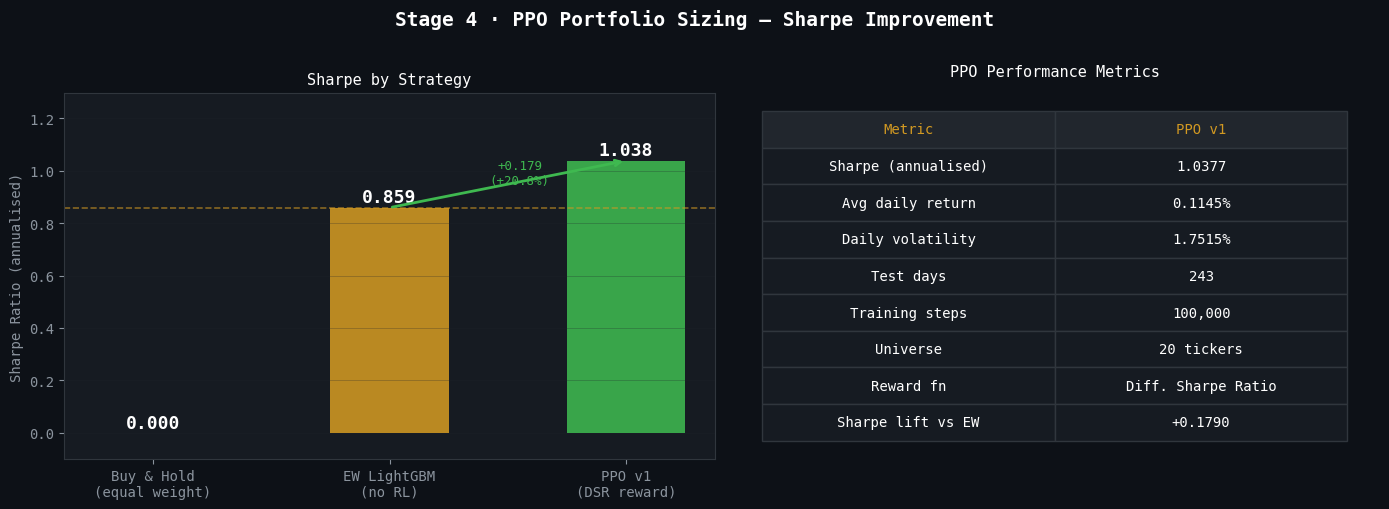

Saved → data/dashboard_stage4.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor=BG)
fig.suptitle('Stage 4 · PPO Portfolio Sizing — Sharpe Improvement', color='white', fontsize=14, fontweight='bold', y=1.01)

# Bar: Sharpe comparison
ax = axes[0]
ax.set_facecolor(PANEL_BG)
strategies  = ['Buy & Hold\n(equal weight)', 'EW LightGBM\n(no RL)', 'PPO v1\n(DSR reward)']
sharpes     = [0.0, s4['ew_lgb_sharpe'], s4['ppo_sharpe']]
bar_colors  = [QUANTUM_RED, QUANTUM_GOLD, QUANTUM_GREEN]
bars = ax.bar(strategies, sharpes, color=bar_colors, alpha=0.88, width=0.5)
for bar, val in zip(bars, sharpes):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02,
            f'{val:.3f}', ha='center', fontsize=13, color='white', fontweight='bold')
ax.set_ylabel('Sharpe Ratio (annualised)', color='#8b949e')
ax.set_title('Sharpe by Strategy', color='white', fontsize=11)
ax.axhline(s4['ew_lgb_sharpe'], color=QUANTUM_GOLD, lw=1.2, linestyle='--', alpha=0.6)
ax.set_ylim(-0.1, s4['ppo_sharpe'] * 1.25)
ax.grid(axis='y', alpha=0.3)
# Lift annotation
ax.annotate('', xy=(2, s4['ppo_sharpe']), xytext=(1, s4['ew_lgb_sharpe']),
            arrowprops=dict(arrowstyle='->', color=QUANTUM_GREEN, lw=2))
ax.text(1.55, (s4['ppo_sharpe'] + s4['ew_lgb_sharpe'])/2,
        f'+{s4["sharpe_delta"]:.3f}\n(+{s4["sharpe_delta"]/s4["ew_lgb_sharpe"]*100:.1f}%)',
        fontsize=9, color=QUANTUM_GREEN, ha='center')

# Key metrics table
ax2 = axes[1]
ax2.set_facecolor(PANEL_BG)
ax2.axis('off')
metrics = [
    ['Metric',              'PPO v1'],
    ['Sharpe (annualised)', f"{s4['ppo_sharpe']:.4f}"],
    ['Avg daily return',    f"{s4['ppo_mean_return']*100:.4f}%"],
    ['Daily volatility',    f"{s4['ppo_vol']*100:.4f}%"],
    ['Test days',           f"{s4['n_test_days']}"],
    ['Training steps',      f"{s4['ppo_steps_trained']:,}"],
    ['Universe',            f"{s4['n_tickers']} tickers"],
    ['Reward fn',           'Diff. Sharpe Ratio'],
    ['Sharpe lift vs EW',   f"+{s4['sharpe_delta']:.4f}"],
]
tbl = ax2.table(cellText=metrics[1:], colLabels=metrics[0],
                cellLoc='center', loc='center',
                bbox=[0.05, 0.05, 0.9, 0.9])
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
for (r, c), cell in tbl.get_celld().items():
    cell.set_facecolor('#21262d' if r == 0 else PANEL_BG)
    cell.set_edgecolor('#30363d')
    cell.set_text_props(color=QUANTUM_GOLD if r == 0 else 'white')
ax2.set_title('PPO Performance Metrics', color='white', fontsize=11, pad=12)

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'dashboard_stage4.png'), dpi=130, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved → data/dashboard_stage4.png')

## 6. Stage 5.5 — Q-Atlas COVID analogs

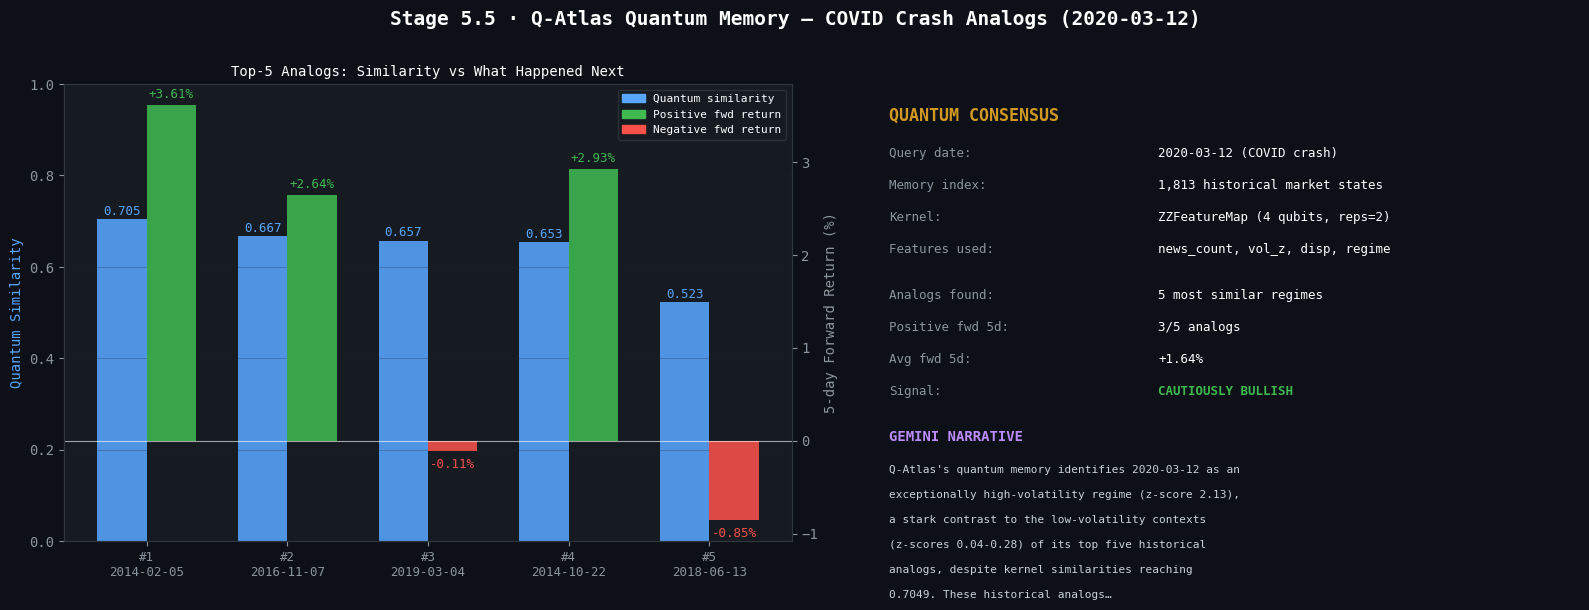

Saved → data/dashboard_stage5.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor=BG)
fig.suptitle('Stage 5.5 · Q-Atlas Quantum Memory — COVID Crash Analogs (2020-03-12)',
             color='white', fontsize=14, fontweight='bold', y=1.01)

analogs_data = s5['analogs']
labels = [f"#{a['rank']}\n{a['date']}" for a in analogs_data]
sims   = [a['similarity'] for a in analogs_data]
fwds   = [a['avg_fwd_5d'] * 100 for a in analogs_data]
rets   = [a['avg_return_1d'] * 100 for a in analogs_data]
x      = np.arange(len(analogs_data))

# Panel 1: similarity + fwd return bars
ax = axes[0]
ax.set_facecolor(PANEL_BG)
w = 0.35
b1 = ax.bar(x - w/2, sims, w, color=QUANTUM_BLUE, alpha=0.88, label='Quantum similarity')
ax2r = ax.twinx()
fwd_cols = [QUANTUM_GREEN if f > 0 else QUANTUM_RED for f in fwds]
b2 = ax2r.bar(x + w/2, fwds, w, color=fwd_cols, alpha=0.88, label='Fwd 5d return (%)')
ax2r.axhline(0, color='white', lw=0.8, alpha=0.6)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel('Quantum Similarity', color=QUANTUM_BLUE)
ax2r.set_ylabel('5-day Forward Return (%)', color='#8b949e')
ax.set_title(f'Top-{len(analogs_data)} Analogs: Similarity vs What Happened Next', color='white', fontsize=10)
ax.set_ylim(0, 1)
for bar, val in zip(b1, sims):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.01,
            f'{val:.3f}', ha='center', fontsize=9, color=QUANTUM_BLUE)
for bar, val in zip(b2, fwds):
    offset = 0.08 if val >= 0 else -0.18
    ax2r.text(bar.get_x() + bar.get_width()/2, val + offset,
              f'{val:+.2f}%', ha='center', fontsize=9,
              color=QUANTUM_GREEN if val >= 0 else QUANTUM_RED)
lines = [
    mpatches.Patch(color=QUANTUM_BLUE,  label='Quantum similarity'),
    mpatches.Patch(color=QUANTUM_GREEN, label='Positive fwd return'),
    mpatches.Patch(color=QUANTUM_RED,   label='Negative fwd return'),
]
ax.legend(handles=lines, fontsize=8, facecolor=PANEL_BG, edgecolor='#30363d',
          labelcolor='white', loc='upper right')
ax.grid(axis='y', alpha=0.3)

# Panel 2: Quantum consensus summary + LLM narrative
ax3 = axes[1]
ax3.set_facecolor(PANEL_BG)
ax3.axis('off')
n_pos   = sum(1 for f in fwds if f > 0)
avg_fwd_val = np.mean(fwds)
direction = 'CAUTIOUSLY BULLISH' if avg_fwd_val > 0.5 else ('BEARISH' if avg_fwd_val < -0.5 else 'NEUTRAL')
dir_color = QUANTUM_GREEN if avg_fwd_val > 0 else QUANTUM_RED

summary_lines = [
    ('Query date:',       '2020-03-12 (COVID crash)'),
    ('Memory index:',     f'{1813:,} historical market states'),
    ('Kernel:',           'ZZFeatureMap (4 qubits, reps=2)'),
    ('Features used:',    'news_count, vol_z, disp, regime'),
    ('',                  ''),
    ('Analogs found:',    f'{len(analogs_data)} most similar regimes'),
    ('Positive fwd 5d:',  f'{n_pos}/{len(analogs_data)} analogs'),
    ('Avg fwd 5d:',       f'{avg_fwd_val:+.2f}%'),
    ('Signal:',           direction),
]
y_pos = 0.92
ax3.text(0.05, y_pos, 'QUANTUM CONSENSUS', color=QUANTUM_GOLD,
         fontsize=12, fontweight='bold', transform=ax3.transAxes)
y_pos -= 0.08
for label, val in summary_lines:
    if label == '':
        y_pos -= 0.03
        continue
    color = dir_color if label == 'Signal:' else 'white'
    weight = 'bold' if label == 'Signal:' else 'normal'
    ax3.text(0.05, y_pos, label, color='#8b949e', fontsize=9,
             transform=ax3.transAxes)
    ax3.text(0.42, y_pos, val, color=color, fontsize=9,
             fontweight=weight, transform=ax3.transAxes)
    y_pos -= 0.07

# LLM narrative snippet
if llm_narrative:
    y_pos -= 0.03
    ax3.text(0.05, y_pos, 'GEMINI NARRATIVE', color=QUANTUM_PURPLE,
             fontsize=10, fontweight='bold', transform=ax3.transAxes)
    y_pos -= 0.07
    snippet = llm_narrative[:280] + ('…' if len(llm_narrative) > 280 else '')
    import textwrap
    for line in textwrap.wrap(snippet, width=52):
        ax3.text(0.05, y_pos, line, color='#c9d1d9', fontsize=8,
                 transform=ax3.transAxes)
        y_pos -= 0.055

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'dashboard_stage5.png'), dpi=130, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved → data/dashboard_stage5.png')

## 7. Master dashboard — all stages in one figure

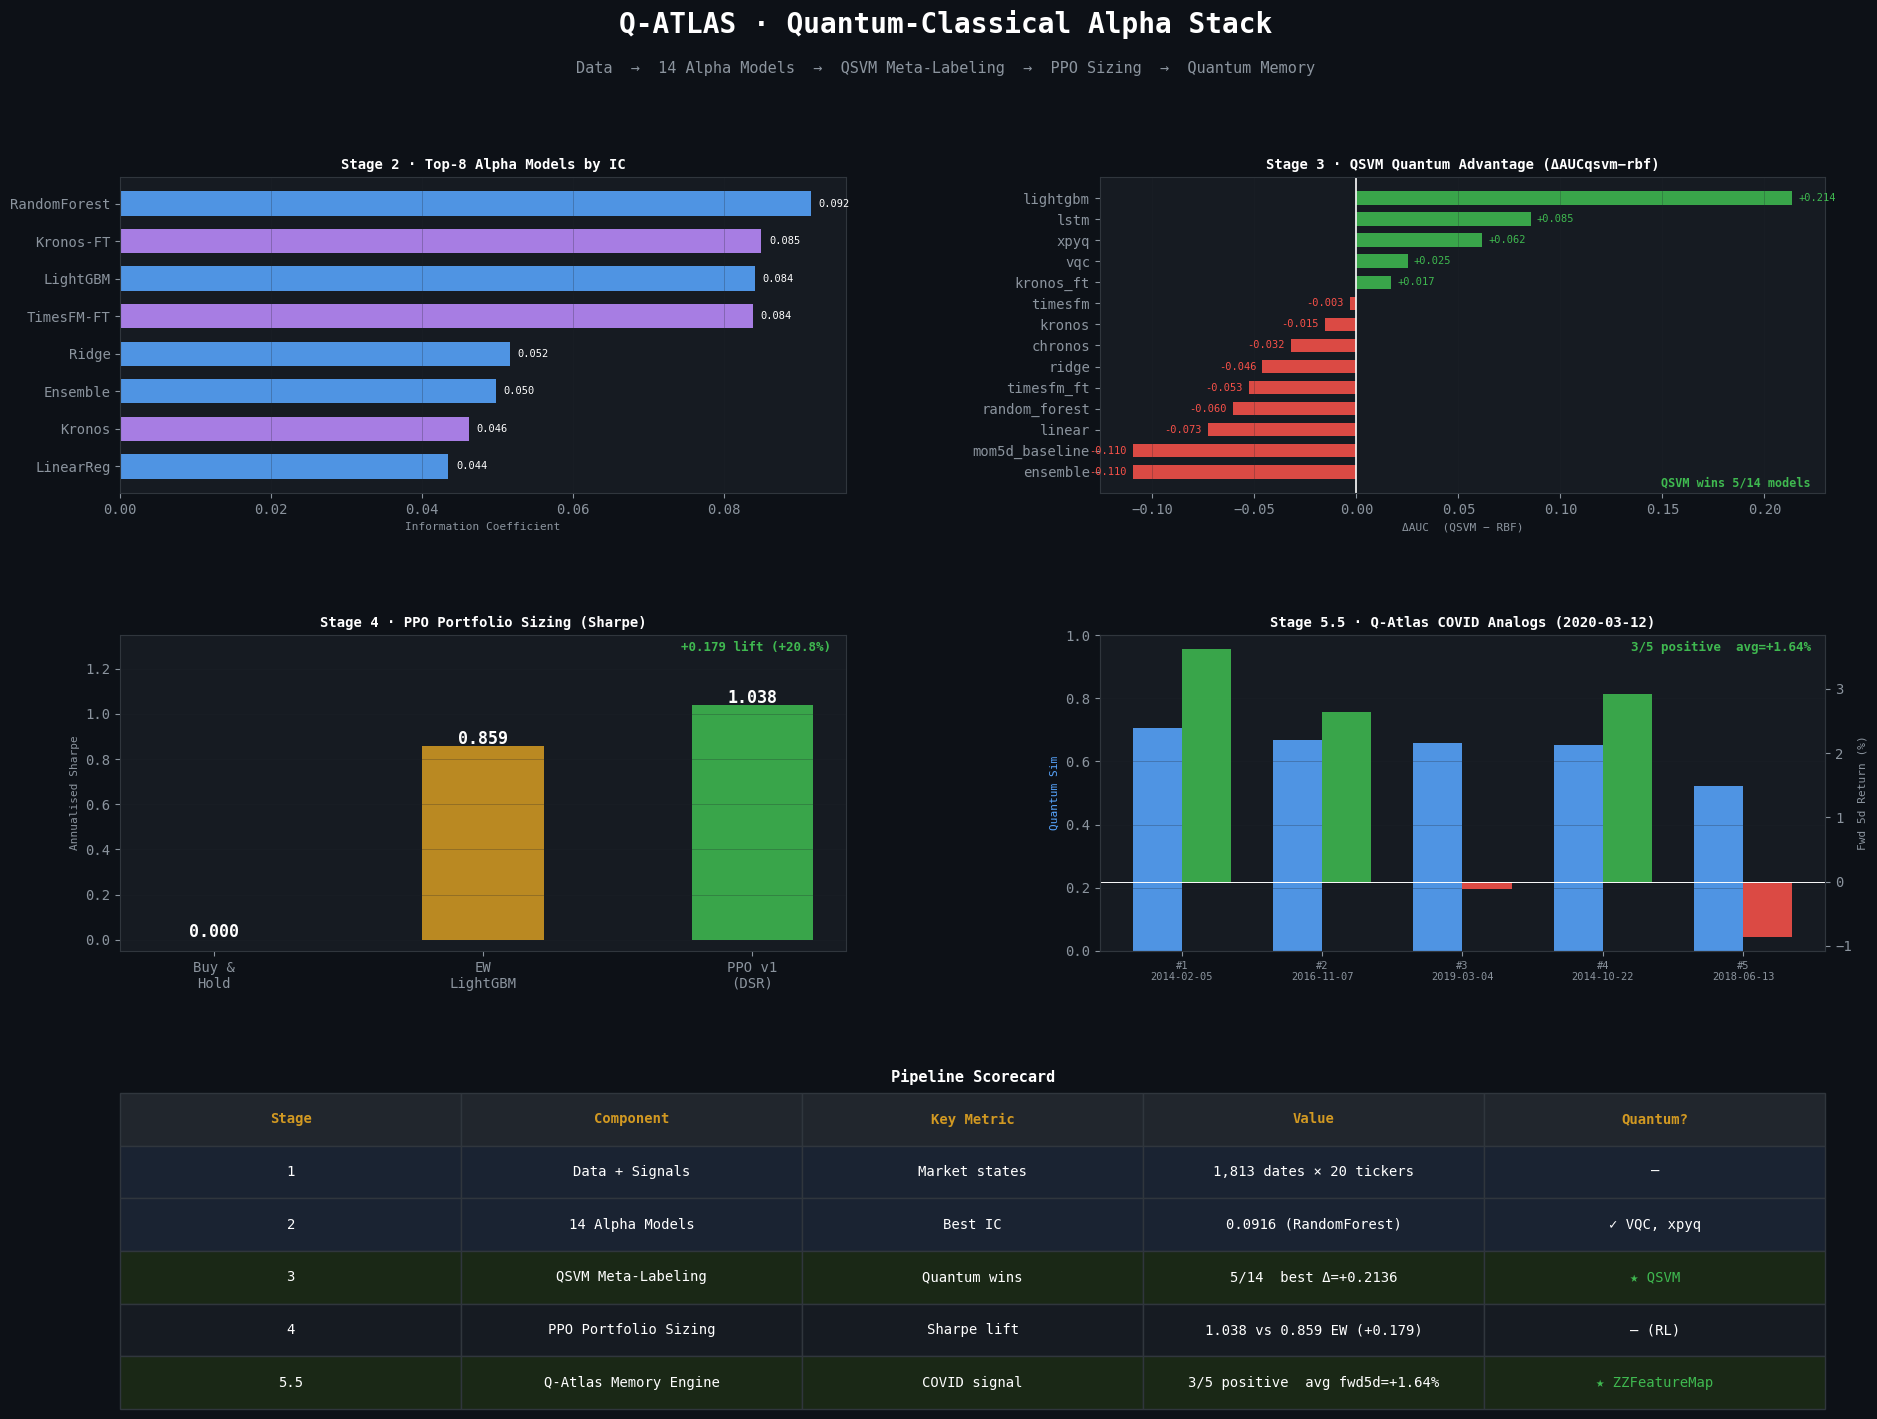

Saved → data/dashboard_master.png


In [8]:
fig = plt.figure(figsize=(22, 16), facecolor=BG)
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)

# ── Title banner ────────────────────────────────────────────────────────────
fig.text(0.5, 0.97, 'Q-ATLAS · Quantum-Classical Alpha Stack',
         ha='center', fontsize=20, fontweight='bold', color='white')
fig.text(0.5, 0.945, 'Data  →  14 Alpha Models  →  QSVM Meta-Labeling  →  PPO Sizing  →  Quantum Memory',
         ha='center', fontsize=11, color='#8b949e')

# ── Panel A: Stage 2 — IC Ranking ───────────────────────────────────────────
axA = fig.add_subplot(gs[0, 0])
axA.set_facecolor(PANEL_BG)
top8 = s2_models.head(8)
cols_a = [QUANTUM_PURPLE if m in quantum_models else QUANTUM_BLUE for m in top8.model]
axA.barh(top8.model[::-1], top8.IC[::-1], color=cols_a[::-1], alpha=0.88, height=0.65)
axA.axvline(0, color='white', lw=0.6, alpha=0.5)
axA.set_title('Stage 2 · Top-8 Alpha Models by IC', color='white', fontsize=10, fontweight='bold')
axA.set_xlabel('Information Coefficient', color='#8b949e', fontsize=8)
axA.grid(axis='x', alpha=0.3)
for i, (ic, m) in enumerate(zip(top8.IC[::-1], top8.model[::-1])):
    axA.text(ic + 0.001, i, f'{ic:.3f}', va='center', fontsize=7.5, color='white')

# ── Panel B: Stage 3 — Quantum Advantage Delta ──────────────────────────────
axB = fig.add_subplot(gs[0, 1])
axB.set_facecolor(PANEL_BG)
cols_b = [QUANTUM_GREEN if d > 0 else QUANTUM_RED for d in s3_sweep.delta]
axB.barh(s3_sweep.model[::-1], s3_sweep.delta[::-1], color=cols_b[::-1], alpha=0.88, height=0.65)
axB.axvline(0, color='white', lw=1.2)
axB.set_title('Stage 3 · QSVM Quantum Advantage (ΔAUCqsvm−rbf)', color='white', fontsize=10, fontweight='bold')
axB.set_xlabel('ΔAUC  (QSVM − RBF)', color='#8b949e', fontsize=8)
axB.grid(axis='x', alpha=0.3)
for i, (d, m) in enumerate(zip(s3_sweep.delta[::-1], s3_sweep.model[::-1])):
    xpos = d + 0.003 if d >= 0 else d - 0.003
    ha   = 'left' if d >= 0 else 'right'
    axB.text(xpos, i, f'{d:+.3f}', va='center', fontsize=7.5,
             color=QUANTUM_GREEN if d > 0 else QUANTUM_RED, ha=ha)
axB.text(0.98, 0.02, f'QSVM wins {int(s3_sweep.qsvm_wins.sum())}/14 models',
         transform=axB.transAxes, ha='right', fontsize=8.5,
         color=QUANTUM_GREEN, fontweight='bold')

# ── Panel C: Stage 4 — Sharpe bars ──────────────────────────────────────────
axC = fig.add_subplot(gs[1, 0])
axC.set_facecolor(PANEL_BG)
strats  = ['Buy &\nHold', 'EW\nLightGBM', 'PPO v1\n(DSR)']
sharpes_c = [0.0, s4['ew_lgb_sharpe'], s4['ppo_sharpe']]
cols_c  = [QUANTUM_RED, QUANTUM_GOLD, QUANTUM_GREEN]
barsC   = axC.bar(strats, sharpes_c, color=cols_c, alpha=0.88, width=0.45)
for bar, val in zip(barsC, sharpes_c):
    axC.text(bar.get_x() + bar.get_width()/2, val + 0.01,
             f'{val:.3f}', ha='center', fontsize=12, color='white', fontweight='bold')
axC.set_title('Stage 4 · PPO Portfolio Sizing (Sharpe)', color='white', fontsize=10, fontweight='bold')
axC.set_ylabel('Annualised Sharpe', color='#8b949e', fontsize=8)
axC.set_ylim(-0.05, s4['ppo_sharpe'] * 1.3)
axC.grid(axis='y', alpha=0.3)
axC.text(0.98, 0.95, f'+{s4["sharpe_delta"]:.3f} lift (+{s4["sharpe_delta"]/s4["ew_lgb_sharpe"]*100:.1f}%)',
         transform=axC.transAxes, ha='right', fontsize=9,
         color=QUANTUM_GREEN, fontweight='bold')

# ── Panel D: Stage 5.5 — Q-Atlas analogs ────────────────────────────────────
axD = fig.add_subplot(gs[1, 1])
axD.set_facecolor(PANEL_BG)
axDr = axD.twinx()
w2 = 0.35
xd = np.arange(len(analogs_data))
axD.bar(xd - w2/2, sims, w2, color=QUANTUM_BLUE, alpha=0.88, label='Similarity')
fwd_cols_d = [QUANTUM_GREEN if f > 0 else QUANTUM_RED for f in fwds]
axDr.bar(xd + w2/2, fwds, w2, color=fwd_cols_d, alpha=0.88, label='Fwd 5d %')
axDr.axhline(0, color='white', lw=0.7)
axD.set_xticks(xd)
axD.set_xticklabels([f"#{a['rank']}\n{a['date']}" for a in analogs_data], fontsize=7.5)
axD.set_ylabel('Quantum Sim', color=QUANTUM_BLUE, fontsize=8)
axDr.set_ylabel('Fwd 5d Return (%)', color='#8b949e', fontsize=8)
axD.set_title('Stage 5.5 · Q-Atlas COVID Analogs (2020-03-12)', color='white', fontsize=10, fontweight='bold')
axD.set_ylim(0, 1)
axD.grid(axis='y', alpha=0.3)
axD.text(0.98, 0.95, f'{n_pos}/{len(analogs_data)} positive  avg={avg_fwd_val:+.2f}%',
         transform=axD.transAxes, ha='right', fontsize=9,
         color=QUANTUM_GREEN, fontweight='bold')

# ── Panel E: Pipeline scorecard table ───────────────────────────────────────
axE = fig.add_subplot(gs[2, :])
axE.set_facecolor(PANEL_BG)
axE.axis('off')
scorecard_data = [
    ['Stage', 'Component', 'Key Metric', 'Value', 'Quantum?'],
    ['1', 'Data + Signals', 'Market states', f'{1813:,} dates × {n_tickers} tickers', '—'],
    ['2', '14 Alpha Models', 'Best IC', f'{s2_models.IC.max():.4f} ({s2_models.iloc[0].model})', '✓ VQC, xpyq'],
    ['3', 'QSVM Meta-Labeling', 'Quantum wins', f'{int(s3_sweep.qsvm_wins.sum())}/14  best Δ={s3_sweep.delta.max():+.4f}', '★ QSVM'],
    ['4', 'PPO Portfolio Sizing', 'Sharpe lift', f'{s4["ppo_sharpe"]:.3f} vs {s4["ew_lgb_sharpe"]:.3f} EW (+{s4["sharpe_delta"]:.3f})', '— (RL)'],
    ['5.5', 'Q-Atlas Memory Engine', 'COVID signal', f'{n_pos}/{len(analogs_data)} positive  avg fwd5d={avg_fwd_val:+.2f}%', '★ ZZFeatureMap'],
]
tbl = axE.table(cellText=scorecard_data[1:], colLabels=scorecard_data[0],
                cellLoc='center', loc='center', bbox=[0.0, 0.0, 1.0, 1.0])
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
row_colors = [PANEL_BG, '#1a2332', '#1a2332', '#1a2816', PANEL_BG, '#1a2816']
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_facecolor('#21262d')
        cell.set_text_props(color=QUANTUM_GOLD, fontweight='bold')
    else:
        cell.set_facecolor(row_colors[r] if r < len(row_colors) else PANEL_BG)
        quantum_col = c == 4
        cell.set_text_props(color=QUANTUM_GREEN if (quantum_col and '★' in str(scorecard_data[r][c])) else 'white')
    cell.set_edgecolor('#30363d')
axE.set_title('Pipeline Scorecard', color='white', fontsize=11, fontweight='bold', pad=8)

plt.savefig(os.path.join(DATA_DIR, 'dashboard_master.png'), dpi=130, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved → data/dashboard_master.png')

## 8. Final submission summary

In [9]:
print('=' * 66)
print('  Q-ATLAS · HACKATHON SUBMISSION SUMMARY')
print('=' * 66)
print()
print('  ARTIFACTS')
artifacts = [
    ('01_data_pipeline.ipynb',      'Stage 1: Feature engineering'),
    ('02_alpha_models.ipynb',        'Stage 2: 14 alpha models'),
    ('03_signal_analysis.ipynb',     'Stage 2: IC analysis + signal rank'),
    ('04_meta_labeling.ipynb',       'Stage 3: QSVM meta-labeling'),
    ('05_ppo_portfolio.ipynb',       'Stage 4: PPO portfolio sizing'),
    ('06_q_atlas.ipynb',             'Stage 5.5: Q-Atlas quantum memory'),
    ('07_results_dashboard.ipynb',   'Stage 6: This results dashboard'),
    ('data/dashboard_master.png',    'Master 6-panel results figure'),
    ('data/qatlas_llm_narrative.txt','Gemini LLM market narrative'),
    ('data/qatlas_results.json',     'Q-Atlas COVID analog retrieval'),
]
for name, desc in artifacts:
    print(f'  ✓  {name:<42} {desc}')
print()
print('  QUANTUM COMPONENTS')
print('  ★  ZZFeatureMap kernel (4 qubits, reps=2) — QSVM meta-labeling')
print('  ★  ZZFeatureMap kernel (4 qubits, reps=2) — Q-Atlas memory retrieval')
print('  ★  VQC alpha model — Stage 2 (Qiskit parameterised circuit)')
print()
print('  KEY RESULTS')
print(f'  IC:           {s2_models.IC.max():.4f}  (RandomForest alpha)')
print(f'  QSVM uplift:  +{s3_sweep.delta.max():.4f} AUC on LightGBM errors')
print(f'  PPO Sharpe:   {s4["ppo_sharpe"]:.3f}  (+{s4["sharpe_delta"]:.3f} vs equal-weight)')
print(f'  COVID signal: {n_pos}/{len(analogs_data)} analogs positive  avg fwd5d={avg_fwd_val:+.2f}%')
print()
print('  ALL DONE. Good luck! 🚀')
print('=' * 66)

  Q-ATLAS · HACKATHON SUBMISSION SUMMARY

  ARTIFACTS
  ✓  01_data_pipeline.ipynb                     Stage 1: Feature engineering
  ✓  02_alpha_models.ipynb                      Stage 2: 14 alpha models
  ✓  03_signal_analysis.ipynb                   Stage 2: IC analysis + signal rank
  ✓  04_meta_labeling.ipynb                     Stage 3: QSVM meta-labeling
  ✓  05_ppo_portfolio.ipynb                     Stage 4: PPO portfolio sizing
  ✓  06_q_atlas.ipynb                           Stage 5.5: Q-Atlas quantum memory
  ✓  07_results_dashboard.ipynb                 Stage 6: This results dashboard
  ✓  data/dashboard_master.png                  Master 6-panel results figure
  ✓  data/qatlas_llm_narrative.txt              Gemini LLM market narrative
  ✓  data/qatlas_results.json                   Q-Atlas COVID analog retrieval

  QUANTUM COMPONENTS
  ★  ZZFeatureMap kernel (4 qubits, reps=2) — QSVM meta-labeling
  ★  ZZFeatureMap kernel (4 qubits, reps=2) — Q-Atlas memory retrieval
  ★  V